# CNN Feature Visualization, Parameter Audit & Critical Analysis
**Deep Learning & Computer Vision – Lab Assignment**

Run all cells top to bottom (`Runtime → Run all`). Works on Colab CPU or GPU, no uploads required.

- **Part I** – 5 kernels × 4 stages (Conv → ReLU → MaxPool → AvgPool) grid
- **Part II** – Model A vs Model B parameter audit (manual vs Keras)
- **Part III** – Supporting code/evidence for Viva Questions 1–5

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import correlate2d
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Part I – Filter pipeline
### 1. Input image
By default a synthetic *building facade* (crisp horizontal + vertical edges, similar to Figure 2) is generated so the notebook runs with no files. To use your own image, set `USE_UPLOAD = True`.

Image shape: (256, 256) | range: 0.07842266 - 0.9885273


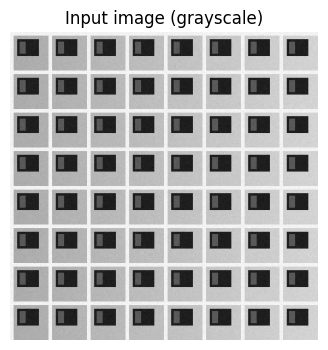

In [2]:
USE_UPLOAD = False   # <-- set True to upload your own image (e.g. the building photo)
IMG_SIZE = 256

def make_facade(n=256):
    img = np.full((n, n), 0.75, dtype=np.float32)            # light concrete wall
    img += np.linspace(-0.08, 0.08, n, dtype=np.float32)[None, :]   # soft gradient
    step = n // 8
    for r in range(8):                                        # windows grid
        for c in range(8):
            y0, x0 = r*step + 6, c*step + 6
            img[y0:y0+step-18, x0:x0+step-14] = 0.12          # dark window
            img[y0+2:y0+step-20, x0+2:x0+7] = 0.35            # inner frame texture
    for c in range(0, n, step):                               # vertical beams
        img[:, c:c+3] = 0.95
    for r in range(0, n, step):                               # horizontal slabs
        img[r:r+3, :] = 0.95
    img += np.random.normal(0, 0.01, img.shape).astype(np.float32)
    return np.clip(img, 0, 1)

if USE_UPLOAD:
    from google.colab import files
    from PIL import Image
    up = files.upload()
    fname = list(up.keys())[0]
    pil = Image.open(fname).convert("L").resize((IMG_SIZE, IMG_SIZE))
    image = np.asarray(pil, dtype=np.float32) / 255.0
else:
    image = make_facade(IMG_SIZE)

print("Image shape:", image.shape, "| range:", image.min(), "-", image.max())
plt.figure(figsize=(4,4)); plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Input image (grayscale)"); plt.axis("off"); plt.show()

### 2. Five 3×3 kernels
*Note:* the **horizontal-edge** kernel responds to horizontal edges (intensity changes along y); the **vertical-edge** kernel responds to vertical edges (changes along x).

In [3]:
kernels = {
    "Horizontal Edge (Sobel-Y)": np.array([[-1,-2,-1],
                                           [ 0, 0, 0],
                                           [ 1, 2, 1]], dtype=np.float32),
    "Vertical Edge (Sobel-X)":   np.array([[-1, 0, 1],
                                           [-2, 0, 2],
                                           [-1, 0, 1]], dtype=np.float32),
    "Sharpen":                   np.array([[ 0,-1, 0],
                                           [-1, 5,-1],
                                           [ 0,-1, 0]], dtype=np.float32),
    "Box Blur":                  np.ones((3,3), dtype=np.float32) / 9.0,
    "Emboss":                    np.array([[-2,-1, 0],
                                           [-1, 1, 1],
                                           [ 0, 1, 2]], dtype=np.float32),
}
for name, k in kernels.items():
    print(name, "\n", k, "\n")

Horizontal Edge (Sobel-Y) 
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]] 

Vertical Edge (Sobel-X) 
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]] 

Sharpen 
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]] 

Box Blur 
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]] 

Emboss 
 [[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]] 



### 3. Pipeline stages A–D
Convolution in CNNs is cross-correlation (kernel is not flipped), implemented with `correlate2d`, zero-padding (`same`).

In [4]:
def conv2d_same(img, k):
    return correlate2d(img, k, mode="same", boundary="fill", fillvalue=0)

def relu(x):
    return np.maximum(0, x)

def pool2x2(x, mode="max"):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2     # crop to even size
    blocks = x[:h, :w].reshape(h // 2, 2, w // 2, 2)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))

results = {}
for name, k in kernels.items():
    A = conv2d_same(image, k)          # Stage A: raw convolution
    B = relu(A)                        # Stage B: post-ReLU
    C = pool2x2(B, "max")              # Stage C: 2x2 max pool, stride 2
    D = pool2x2(B, "avg")              # Stage D: 2x2 avg pool, stride 2
    results[name] = dict(A=A, B=B, C=C, D=D)
    print(f"{name:28s} A{A.shape} B{B.shape} C{C.shape} D{D.shape} | "
          f"A range [{A.min():.2f}, {A.max():.2f}] | zeros after ReLU: {(B==0).mean()*100:.1f}%")

Horizontal Edge (Sobel-Y)    A(256, 256) B(256, 256) C(128, 128) D(128, 128) | A range [-3.83, 3.88] | zeros after ReLU: 50.3%
Vertical Edge (Sobel-X)      A(256, 256) B(256, 256) C(128, 128) D(128, 128) | A range [-3.85, 3.87] | zeros after ReLU: 47.5%
Sharpen                      A(256, 256) B(256, 256) C(128, 128) D(128, 128) | A range [-1.40, 2.86] | zeros after ReLU: 8.9%
Box Blur                     A(256, 256) B(256, 256) C(128, 128) D(128, 128) | A range [0.11, 0.96] | zeros after ReLU: 0.0%
Emboss                       A(256, 256) B(256, 256) C(128, 128) D(128, 128) | A range [-2.69, 4.75] | zeros after ReLU: 10.9%


### 4. 5 × 4 comparison grid
Stage A uses its own symmetric diverging scale (negatives visible). Stages B, C, D share the **same** intensity scale within each row (0 → max of Stage B) for consistent comparison.

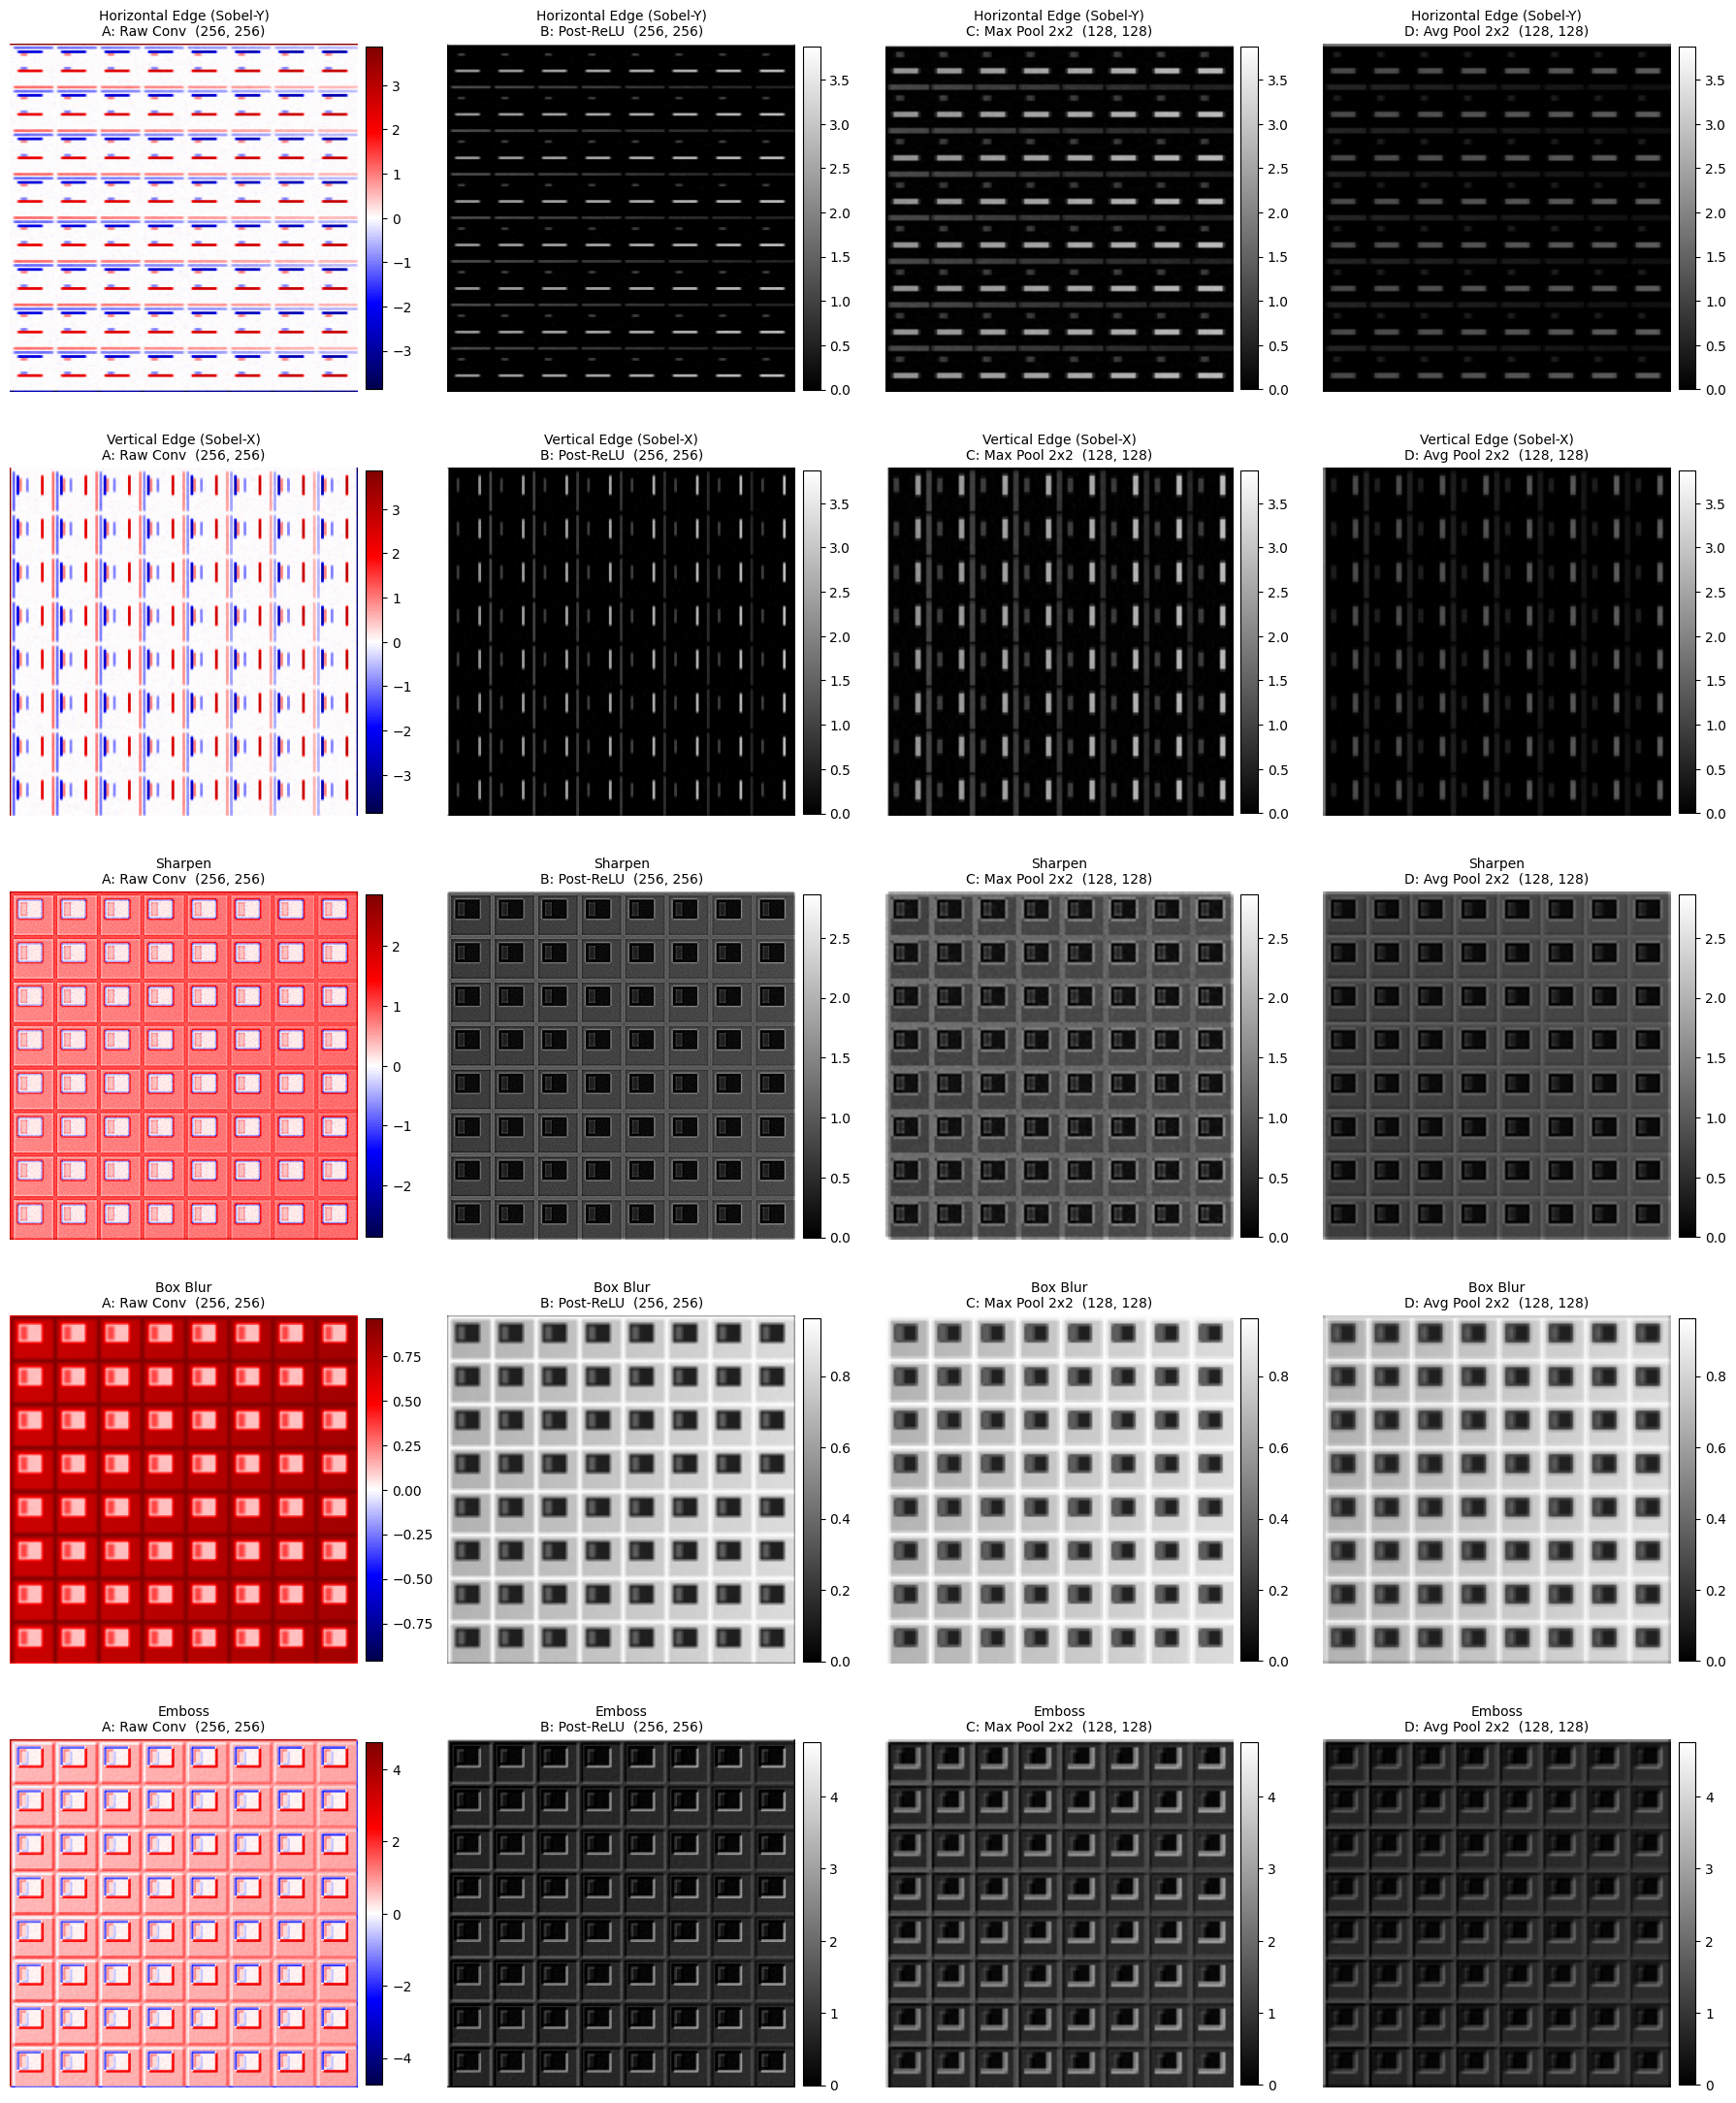

Saved: cnn_5x4_grid.png


In [5]:
stage_titles = ["A: Raw Conv", "B: Post-ReLU", "C: Max Pool 2x2", "D: Avg Pool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(18, 22))

for i, (name, r) in enumerate(results.items()):
    amax = np.abs(r["A"]).max() + 1e-8
    bmax = r["B"].max() + 1e-8
    for j, key in enumerate("ABCD"):
        ax = axes[i, j]
        if key == "A":
            im = ax.imshow(r[key], cmap="seismic", vmin=-amax, vmax=amax)
        else:
            im = ax.imshow(r[key], cmap="gray", vmin=0, vmax=bmax)
        ax.set_title(f"{name}\n{stage_titles[j]}  {r[key].shape}", fontsize=10)
        ax.axis("off")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

plt.tight_layout()
plt.savefig("cnn_5x4_grid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: cnn_5x4_grid.png")

## Part II – Architecture comparison & parameter audit
Formula: `Params per Conv layer = (Kh × Kw × Cin + 1) × Cout`.

Architecture: `Input(32,32,3) → Conv(5) → ReLU → Pool → Conv(10) → ReLU → Pool → GlobalAvgPool → Dense(10)`.
Dense layer params = `(Cin + 1) × 10`.

In [6]:
def conv_params(kh, kw, cin, cout):
    return (kh * kw * cin + 1) * cout

def dense_params(nin, nout):
    return (nin + 1) * nout

def manual_count(k):
    c1 = conv_params(k, k, 3, 5)
    c2 = conv_params(k, k, 5, 10)
    d  = dense_params(10, 10)
    print(f"Kernel {k}x{k}:")
    print(f"  Conv1 = ({k}*{k}*3 + 1) * 5  = {c1}")
    print(f"  Conv2 = ({k}*{k}*5 + 1) * 10 = {c2}")
    print(f"  Dense = (10 + 1) * 10        = {d}")
    print(f"  Pooling / GAP / ReLU         = 0")
    print(f"  TOTAL                        = {c1 + c2 + d}\n")
    return c1 + c2 + d, c1 + c2

manual_A, manual_A_conv = manual_count(3)
manual_B, manual_B_conv = manual_count(5)

Kernel 3x3:
  Conv1 = (3*3*3 + 1) * 5  = 140
  Conv2 = (3*3*5 + 1) * 10 = 460
  Dense = (10 + 1) * 10        = 110
  Pooling / GAP / ReLU         = 0
  TOTAL                        = 710

Kernel 5x5:
  Conv1 = (5*5*3 + 1) * 5  = 380
  Conv2 = (5*5*5 + 1) * 10 = 1260
  Dense = (10 + 1) * 10        = 110
  Pooling / GAP / ReLU         = 0
  TOTAL                        = 1750



In [7]:
def build_model(kernel_size, pool_type, name):
    Pool = layers.MaxPooling2D if pool_type == "max" else layers.AveragePooling2D
    return keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(5,  kernel_size, padding="same", activation="relu"),
        Pool(pool_size=2, strides=2),
        layers.Conv2D(10, kernel_size, padding="same", activation="relu"),
        Pool(pool_size=2, strides=2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10, activation="softmax"),
    ], name=name)

model_A = build_model(3, "max", "Model_A_Standard")
model_B = build_model(5, "avg", "Model_B_LargeKernel")

model_A.summary()
model_B.summary()

Model: "Model_A_Standard"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_LargeKernel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 16, 16, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 8, 8, 10)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
code_A, code_B = model_A.count_params(), model_B.count_params()

audit = pd.DataFrame([
    ["Model A (Standard)",     "Conv1: 5, Conv2: 10", "3 x 3", "Max Pooling (2x2, s2)", manual_A, code_A],
    ["Model B (Large Kernel)", "Conv1: 5, Conv2: 10", "5 x 5", "Avg Pooling (2x2, s2)", manual_B, code_B],
], columns=["Model", "Conv Architecture", "Kernel", "Pooling", "Manual Count", "Code Output"])
display(audit)

assert manual_A == code_A and manual_B == code_B, "Manual and Keras counts differ!"
print("Manual counts match Keras summary.")

,Model,Conv Architecture,Kernel,Pooling,Manual Count,Code Output
0,Model A (Standard),"Conv1: 5, Conv2: 10",3 x 3,"Max Pooling (2x2, s2)",710,710
1,Model B (Large Kernel),"Conv1: 5, Conv2: 10",5 x 5,"Avg Pooling (2x2, s2)",1750,1750


Manual counts match Keras summary.


## Part III – Evidence code for Viva Questions

### Q1 – ReLU blackout, Leaky ReLU (α=0.1), Sigmoid

Horizontal Edge (Sobel-Y): negative pixels = 50.3%, zeroed by ReLU = 50.3%, min=-3.83, max=3.88
Vertical Edge (Sobel-X): negative pixels = 47.5%, zeroed by ReLU = 47.5%, min=-3.85, max=3.87


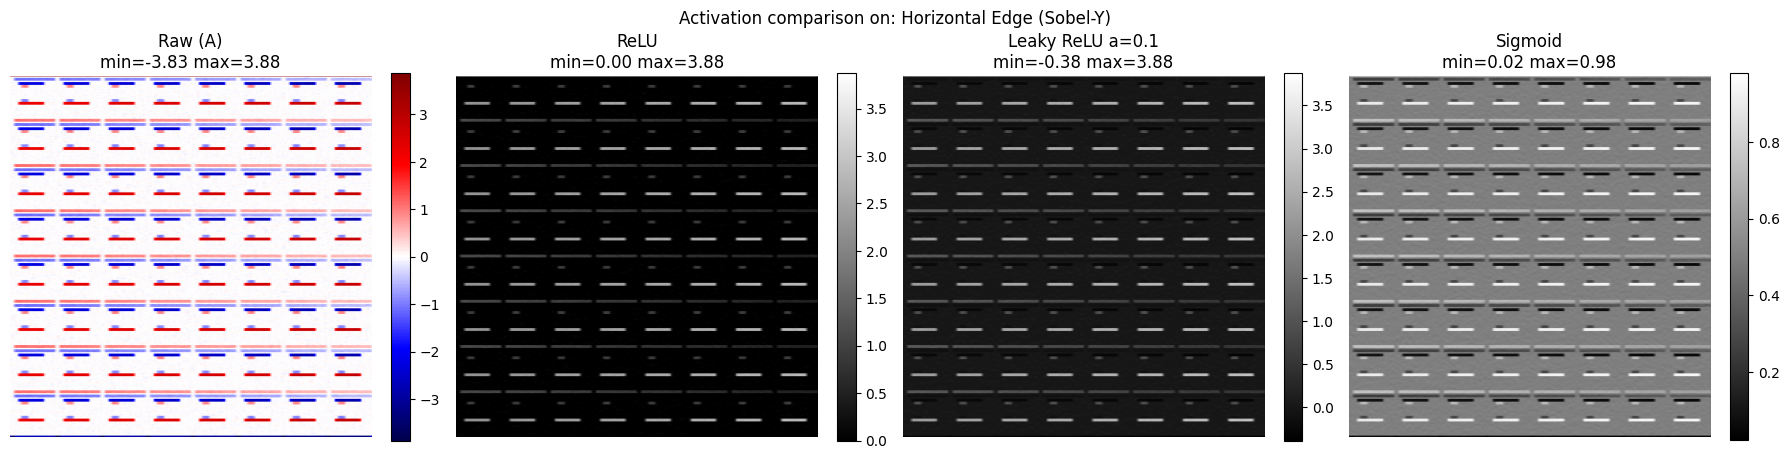

Sigmoid maps zero-response (flat regions) to 0.5 -> never truly black; saturates for large |x|.


In [9]:
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))

for name in ["Horizontal Edge (Sobel-Y)", "Vertical Edge (Sobel-X)"]:
    A = results[name]["A"]
    print(f"{name}: negative pixels = {(A<0).mean()*100:.1f}%, "
          f"zeroed by ReLU = {(relu(A)==0).mean()*100:.1f}%, min={A.min():.2f}, max={A.max():.2f}")

name = "Horizontal Edge (Sobel-Y)"
A = results[name]["A"]
acts = {"Raw (A)": A, "ReLU": relu(A), "Leaky ReLU a=0.1": leaky_relu(A), "Sigmoid": sigmoid(A)}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (t, m) in zip(axes, acts.items()):
    if t == "Raw (A)":
        v = np.abs(m).max(); im = ax.imshow(m, cmap="seismic", vmin=-v, vmax=v)
    else:
        im = ax.imshow(m, cmap="gray")
    ax.set_title(f"{t}\nmin={m.min():.2f} max={m.max():.2f}"); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle(f"Activation comparison on: {name}"); plt.tight_layout(); plt.show()
print("Sigmoid maps zero-response (flat regions) to 0.5 -> never truly black; saturates for large |x|.")

### Q2 – Max vs Average pooling (Sharpen / Edge rows, and dark-ink-on-white text)

Sharpen: peak max-pool = 2.86, peak avg-pool = 1.91, mean max-pool = 0.859, mean avg-pool = 0.692
Horizontal Edge (Sobel-Y): peak max-pool = 3.88, peak avg-pool = 1.95, mean max-pool = 0.342, mean avg-pool = 0.162


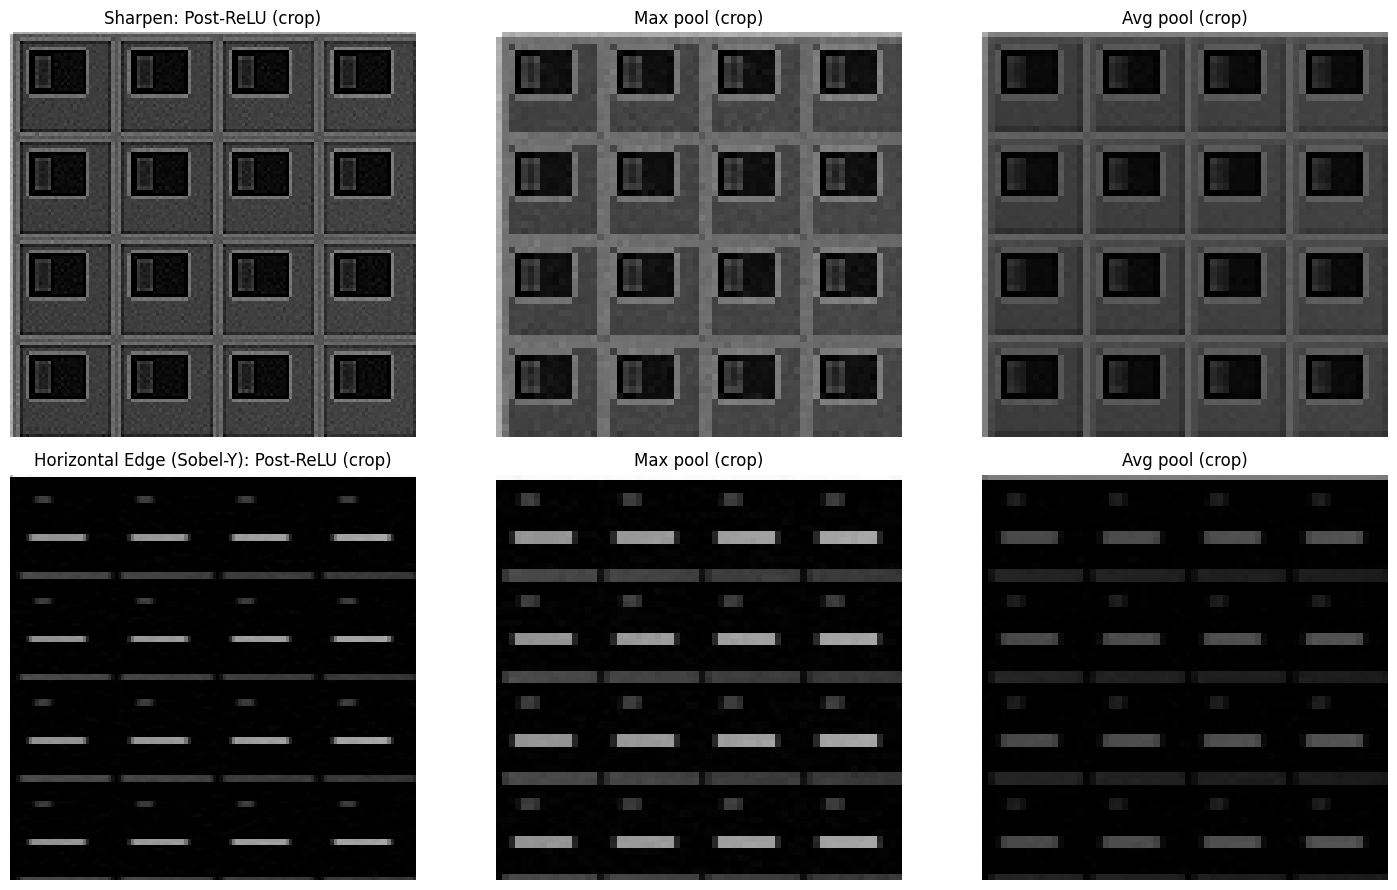

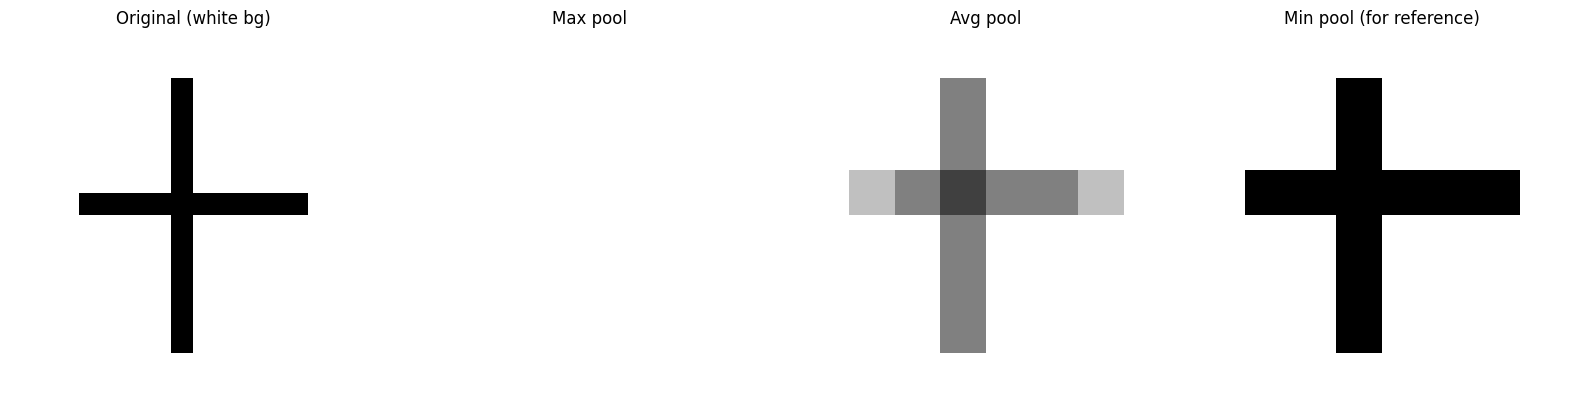

Dark pixels (<128) -> original: 21 | max: 0 | avg: 9 | min: 11
Max pooling picks the brightest (white) pixel in each window, erasing thin dark strokes; avg pooling keeps them as gray.


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, name in enumerate(["Sharpen", "Horizontal Edge (Sobel-Y)"]):
    r = results[name]; m = r["B"].max()
    axes[i,0].imshow(r["B"][:128,:128], cmap="gray", vmin=0, vmax=m); axes[i,0].set_title(f"{name}: Post-ReLU (crop)")
    axes[i,1].imshow(r["C"][:64,:64],   cmap="gray", vmin=0, vmax=m); axes[i,1].set_title("Max pool (crop)")
    axes[i,2].imshow(r["D"][:64,:64],   cmap="gray", vmin=0, vmax=m); axes[i,2].set_title("Avg pool (crop)")
    for a in axes[i]: a.axis("off")
    print(f"{name}: peak max-pool = {r['C'].max():.2f}, peak avg-pool = {r['D'].max():.2f}, "
          f"mean max-pool = {r['C'].mean():.3f}, mean avg-pool = {r['D'].mean():.3f}")
plt.tight_layout(); plt.show()

# Dark text on white background (white=255)
text = np.full((16, 16), 255.0)
text[2:14, 7] = 0        # thin vertical stroke (1 px)
text[7, 3:13] = 0        # thin horizontal stroke
mx, av = pool2x2(text, "max"), pool2x2(text, "avg")
mn = -pool2x2(-text, "max")   # min pooling
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (t, m) in zip(axes, [("Original (white bg)", text), ("Max pool", mx), ("Avg pool", av), ("Min pool (for reference)", mn)]):
    ax.imshow(m, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("Dark pixels (<128) -> original:", (text<128).sum(), "| max:", (mx<128).sum(), "| avg:", (av<128).sum(), "| min:", (mn<128).sum())
print("Max pooling picks the brightest (white) pixel in each window, erasing thin dark strokes; avg pooling keeps them as gray.")

### Q3 – Parameter increase and receptive field equivalence

In [11]:
inc_total = (manual_B - manual_A) / manual_A * 100
inc_conv  = (manual_B_conv - manual_A_conv) / manual_A_conv * 100
print(f"Model A total = {manual_A}, Model B total = {manual_B}")
print(f"Increase (total incl. Dense)   : {manual_B - manual_A} params = {inc_total:.2f}%")
print(f"Increase (conv layers only)    : {manual_B_conv - manual_A_conv} params = {inc_conv:.2f}%")

# Receptive field: n stacked 3x3 (stride 1) -> RF = 1 + 2n ; need 5 -> n = 2
n_layers = (5 - 1) // 2
print(f"\nStacked 3x3 layers needed for 5x5 receptive field: {n_layers}")

print("\nPer-layer saving for C input & C output channels (ignoring bias): 25*C^2 vs 2*9*C^2 = 18*C^2 -> 28% fewer.")
for C in [1, 5, 10, 64]:
    single = (5*5*C + 1) * C
    stacked = (3*3*C + 1) * C + (3*3*C + 1) * C
    print(f"  C={C:3d}: 5x5 = {single:6d} | two 3x3 = {stacked:6d} | saved = {single-stacked:6d} ({(single-stacked)/single*100:.1f}%)")

print("\nSame-width comparison (C in = C out) is the fair one: two 3x3 layers save ~28% weights vs one 5x5, and add an extra ReLU (more non-linearity).")

Model A total = 710, Model B total = 1750
Increase (total incl. Dense)   : 1040 params = 146.48%
Increase (conv layers only)    : 1040 params = 173.33%

Stacked 3x3 layers needed for 5x5 receptive field: 2

Per-layer saving for C input & C output channels (ignoring bias): 25*C^2 vs 2*9*C^2 = 18*C^2 -> 28% fewer.
  C=  1: 5x5 =     26 | two 3x3 =     20 | saved =      6 (23.1%)
  C=  5: 5x5 =    630 | two 3x3 =    460 | saved =    170 (27.0%)
  C= 10: 5x5 =   2510 | two 3x3 =   1820 | saved =    690 (27.5%)
  C= 64: 5x5 = 102464 | two 3x3 =  73856 | saved =  28608 (27.9%)

Same-width comparison (C in = C out) is the fair one: two 3x3 layers save ~28% weights vs one 5x5, and add an extra ReLU (more non-linearity).


### Q4 – Order invariance: Conv→ReLU→MaxPool vs Conv→MaxPool→ReLU

In [12]:
patch = np.array([[-3.0, -1.0],
                  [-2.0,  4.0]])
neg_patch = np.array([[-3.0, -1.0],
                      [-2.0, -5.0]])

for p in [patch, neg_patch]:
    a = np.max(np.maximum(0, p))     # ReLU then MaxPool
    b = np.maximum(0, np.max(p))     # MaxPool then ReLU
    print(f"patch=\n{p}\n ReLU->Max = {a} | Max->ReLU = {b} | identical: {a == b}\n")

# Whole-image numerical check (both orders), random test patches too
for name, r in results.items():
    A = r["A"]
    order1 = pool2x2(relu(A), "max")
    order2 = relu(pool2x2(A, "max"))
    print(f"{name:28s} identical: {np.array_equal(order1, order2)}")

rand = np.random.randn(100000, 4)
print("Random test (100k patches) identical:", np.array_equal(np.maximum(0, rand).max(1), np.maximum(0, rand.max(1))))

print("""
Proof: ReLU is monotonically non-decreasing, so max(ReLU(x_i)) = ReLU(max(x_i)).
Efficiency: MaxPool first -> ReLU on 1/4 of elements (2x2 pool) instead of all.
NOTE: this does NOT hold for Average Pooling (ReLU(mean) != mean(ReLU)).""")

# Avg pooling counter-example
p = np.array([[-3.0, 4.0], [-2.0, 1.0]])
print("Avg: ReLU->Avg =", np.maximum(0, p).mean(), "| Avg->ReLU =", np.maximum(0, p.mean()))

patch=
[[-3. -1.]
 [-2.  4.]]
 ReLU->Max = 4.0 | Max->ReLU = 4.0 | identical: True

patch=
[[-3. -1.]
 [-2. -5.]]
 ReLU->Max = 0.0 | Max->ReLU = 0.0 | identical: True

Horizontal Edge (Sobel-Y)    identical: True
Vertical Edge (Sobel-X)      identical: True
Sharpen                      identical: True
Box Blur                     identical: True
Emboss                       identical: True
Random test (100k patches) identical: True

Proof: ReLU is monotonically non-decreasing, so max(ReLU(x_i)) = ReLU(max(x_i)).
Efficiency: MaxPool first -> ReLU on 1/4 of elements (2x2 pool) instead of all.
NOTE: this does NOT hold for Average Pooling (ReLU(mean) != mean(ReLU)).
Avg: ReLU->Avg = 1.25 | Avg->ReLU = 0.0


### Q5 – Detecting filter redundancy (collapse)

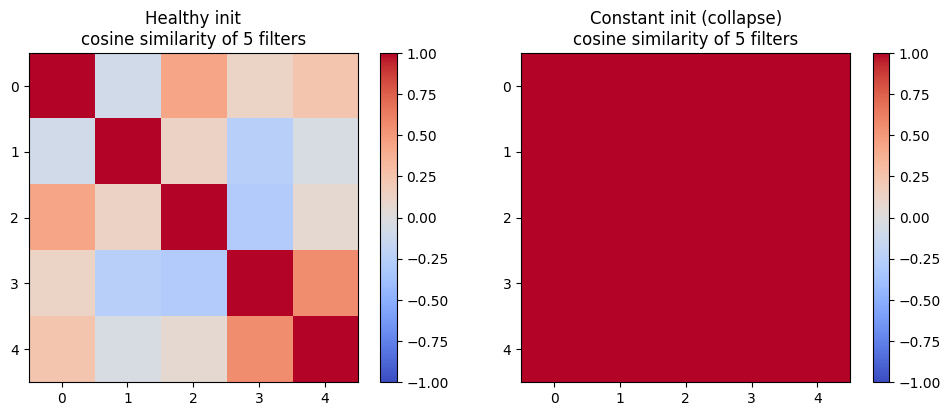

Root cause 1: poor weight initialization (zeros/identical weights -> identical gradients, symmetry never breaks).
  Fix: He/Glorot random initialization (kernel_initializer='he_normal'), optionally BatchNorm.
Root cause 2: dead ReLUs / too-high learning rate (large update pushes pre-activations negative -> zero gradient forever).
  Fix: lower LR (e.g. 1e-3 with Adam + warmup/decay), use LeakyReLU/ELU, BatchNorm, proper input normalization.
Also monitor: fraction of zero activations per filter and the cosine-similarity matrix above.


In [13]:
def filter_similarity(model, layer_idx=0):
    W = model.layers[layer_idx].get_weights()[0]          # (kh, kw, cin, cout)
    F = W.reshape(-1, W.shape[-1]).T                       # (cout, features)
    F = F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-8)
    return F @ F.T

# Healthy init (Glorot/He) vs bad init (all weights identical -> symmetric, collapse)
healthy = build_model(3, "max", "healthy")
bad = build_model(3, "max", "bad")
conv = bad.layers[0]
w, b = conv.get_weights()
conv.set_weights([np.full_like(w, 0.05), np.zeros_like(b)])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (t, m) in zip(axes, [("Healthy init", healthy), ("Constant init (collapse)", bad)]):
    S = filter_similarity(m)
    im = ax.imshow(S, vmin=-1, vmax=1, cmap="coolwarm"); ax.set_title(t + "\ncosine similarity of 5 filters")
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

print("""Root cause 1: poor weight initialization (zeros/identical weights -> identical gradients, symmetry never breaks).
  Fix: He/Glorot random initialization (kernel_initializer='he_normal'), optionally BatchNorm.
Root cause 2: dead ReLUs / too-high learning rate (large update pushes pre-activations negative -> zero gradient forever).
  Fix: lower LR (e.g. 1e-3 with Adam + warmup/decay), use LeakyReLU/ELU, BatchNorm, proper input normalization.
Also monitor: fraction of zero activations per filter and the cosine-similarity matrix above.""")